# 4. New method: gradient boosting

Random Forest (class) builds trees **independently** and averages them (bagging).
Gradient boosting builds trees **one after another**; each new tree fits the errors the previous
trees still make. We use the histogram-based variant (the LightGBM algorithm, as implemented in
scikit-learn), which handles missing values natively.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from workflow_ml.config import LABELS
from workflow_ml.features import load_table
from workflow_ml.split import patient_folds
from workflow_ml.train import BASE_MODELS, cached_scores, out_of_fold_decisions
from workflow_ml.evaluate import score_table

table = load_table()
folds = patient_folds(table)
y_true = table[list(LABELS)].to_numpy()


def evaluate(name, make_model=None):
    """Out-of-fold scores and metrics for one model (cached after the first run)."""
    scores = cached_scores(name, make_model or BASE_MODELS[name], table, folds)
    decisions = out_of_fold_decisions(scores, y_true, folds)
    return scores, score_table(y_true, scores, decisions).assign(model=name)

In [3]:
boosting_scores, boosting_metrics = evaluate("gradient_boosting")
forest_scores, forest_metrics = evaluate("random_forest")
print("mean F1  boosting:", boosting_metrics["f1"].mean().round(3), "| random forest:", forest_metrics["f1"].mean().round(3))
boosting_metrics[["label", "precision", "recall", "f1", "pr_auc", "roc_auc"]].round(3)

mean F1  boosting: 0.783 | random forest: 0.745


,label,precision,recall,f1,pr_auc,roc_auc
0,medical_exam,0.622,0.788,0.695,0.771,0.936
1,lab_test,0.860,0.858,0.859,0.945,0.981
2,imaging,0.739,0.731,0.735,0.739,0.937
3,instrument_test,0.817,0.866,0.841,0.765,0.973


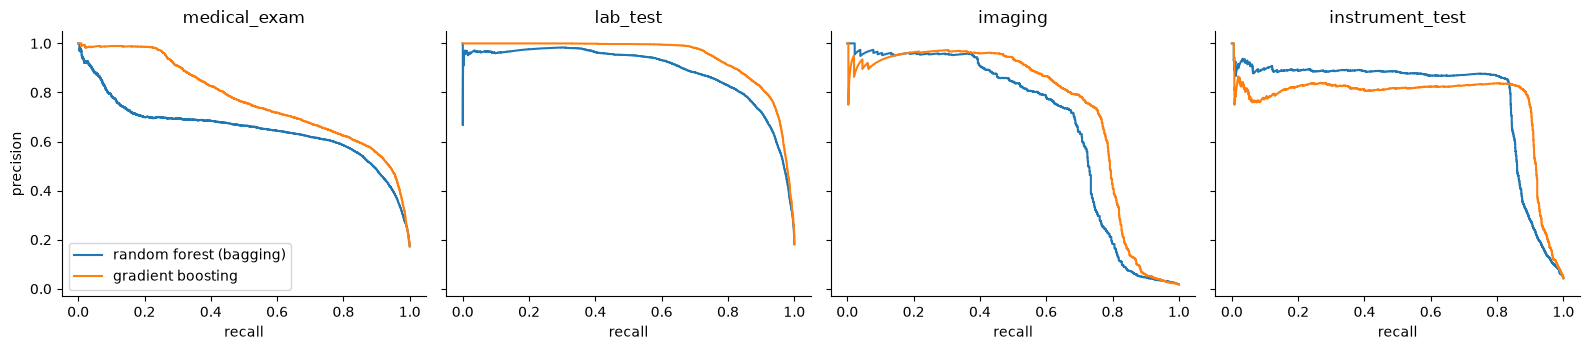

In [4]:
curves = {"random forest (bagging)": forest_scores, "gradient boosting": boosting_scores}

from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for column, (label, ax) in enumerate(zip(LABELS, axes)):
    for name, scores in curves.items():
        precision, recall, _ = precision_recall_curve(y_true[:, column], scores[:, column])
        ax.plot(recall, precision, label=name)
    ax.set(title=label, xlabel="recall")
axes[0].set_ylabel("precision")
axes[0].legend()
plt.tight_layout()

## Do PCA + K-Means phenotypes help?

PCA (class) compresses the features to 20 components, K-Means (class) groups encounters into 16
patient-state clusters, and the cluster plus the distance to every centre are added as features.

In [5]:
from workflow_ml.models.boosting import BoostingModel

phenotype_scores, phenotype_metrics = evaluate(
    "gradient_boosting_phenotypes", lambda: BoostingModel(phenotypes=True))
pd.DataFrame({
    "boosting": boosting_metrics.set_index("label")["f1"],
    "boosting + phenotypes": phenotype_metrics.set_index("label")["f1"],
}).round(3).T.assign(mean_f1=lambda frame: frame.mean(axis=1).round(3))

label,medical_exam,lab_test,imaging,instrument_test,mean_f1
boosting,0.695,0.859,0.735,0.841,0.782
boosting + phenotypes,0.685,0.861,0.732,0.848,0.782
